# Machine Learning Assignement #2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [3]:
sns.set_style("whitegrid")

In [4]:
# Loading the datatset
df = pd.read_csv("fma_dataset_filtered.csv")

In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (2406, 524)


In [6]:
print(df.head())

   track_id  chroma_cens_kurtosis_01  chroma_cens_kurtosis_02  \
0         2                 7.180653                 5.230309   
1         3                 1.888963                 0.760539   
2         5                 0.527563                -0.077654   
3       134                 0.918445                 0.674147   
4       139                -0.020869                 0.432330   

   chroma_cens_kurtosis_03  chroma_cens_kurtosis_04  chroma_cens_kurtosis_05  \
0                 0.249321                 1.347620                 1.482478   
1                 0.345297                 2.295201                 1.654031   
2                -0.279610                 0.685883                 1.937570   
3                 0.577818                 1.281117                 0.933746   
4                 0.331278                 0.829845                 2.625593   

   chroma_cens_kurtosis_06  chroma_cens_kurtosis_07  chroma_cens_kurtosis_08  \
0                 0.531371                 1.481

In [7]:
# Preprocessing

y = df['genre'].copy()
X = df.drop(columns=['genre']).copy()

In [8]:
X = X.dropna()     # Remove missing values
y = y.loc[X.index]

In [9]:
# Standardize features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
print("Preprocessed feature matrix shape:", X_scaled.shape)
print("Number of unique genres:", y.nunique())

Preprocessed feature matrix shape: (2406, 523)
Number of unique genres: 4


## Visualization with PCA and t-SNE (2D and 3D)

### Principal Component Analysis (PCA)

In [11]:
# Fit PCA with enough components for visualization
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

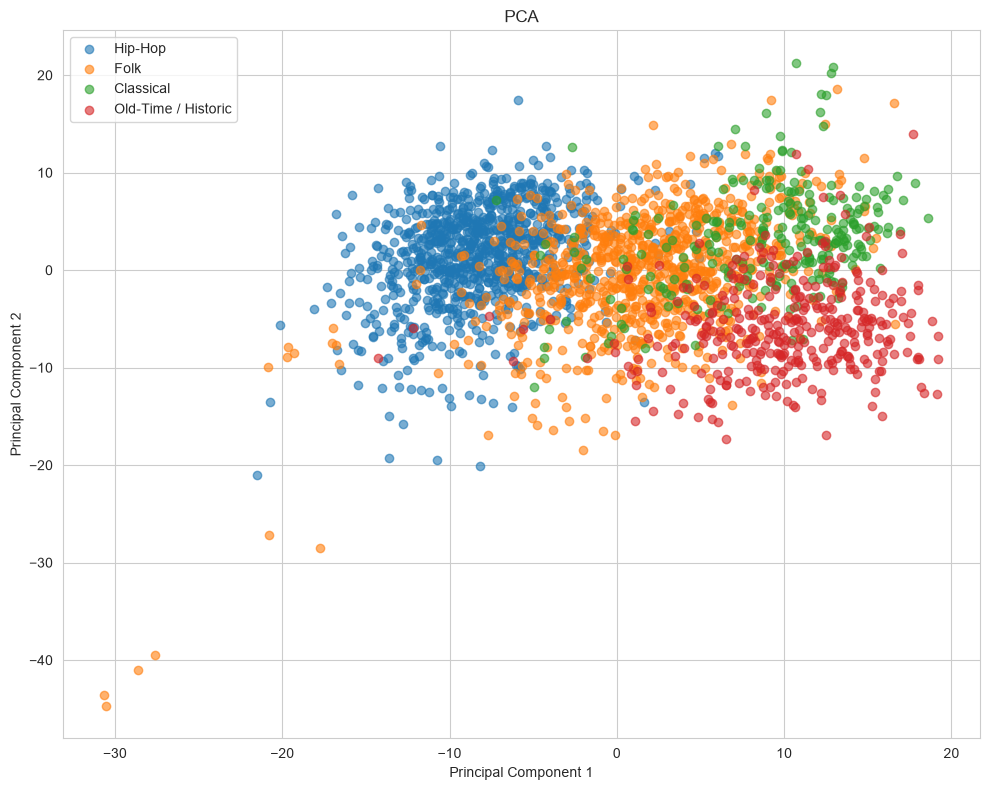

In [12]:
# PCA plot
plt.figure(figsize=(10, 8))
for genre in y.unique():
    mask = (y == genre).values    # (y == genre) returns a boolean array same length as y ([True, False...  ])
    plt.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], label=genre, alpha=0.6)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### t-distributed Stochastic Neighbor Embedding (t-SNE) 

t-SNE is computationally expensive on high-dimensional data, so we first reduce to 50 principal components.

In [13]:
# Pre-reduce to 50 components for t-SNE and K-means
pca_50 = PCA(n_components=50, random_state=42)
X_pca_50 = pca_50.fit_transform(X_scaled)

In [14]:
# 2D t-SNE
tsne_2d = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne_2d = tsne_2d.fit_transform(X_pca_50)


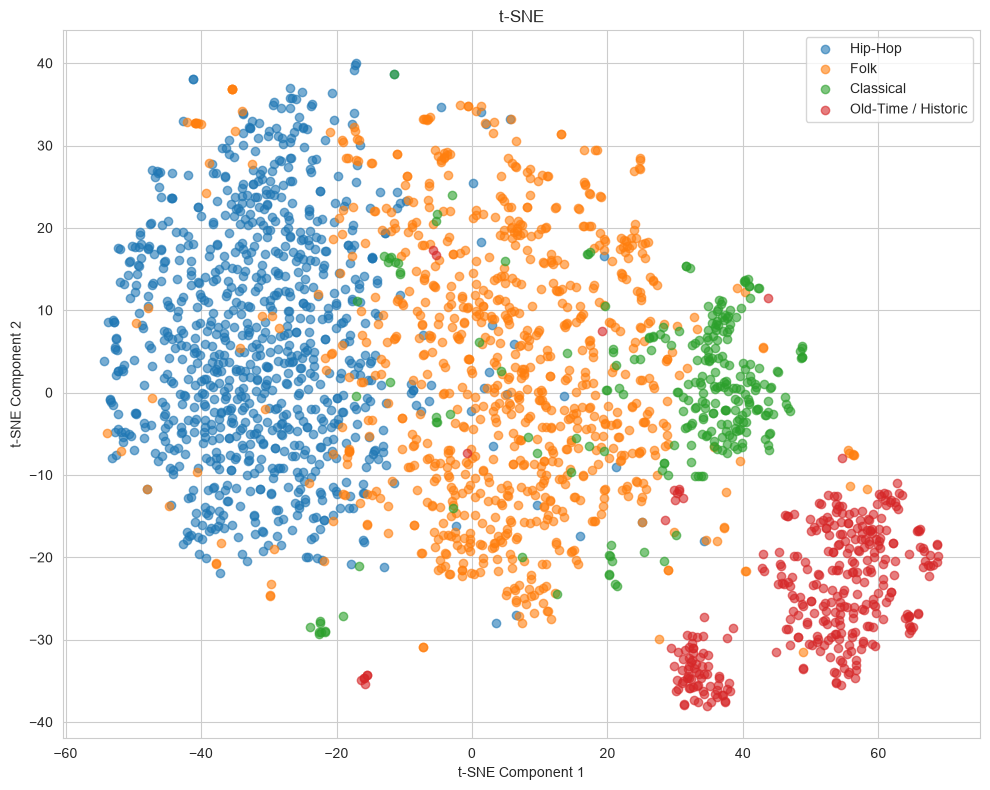

In [15]:
plt.figure(figsize=(10, 8))
for genre in y.unique():
    mask = (y == genre).values
    plt.scatter(X_tsne_2d[mask, 0], X_tsne_2d[mask, 1], label=genre, alpha=0.6)
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE")
plt.legend()
plt.tight_layout()
plt.show()

### PCA explained variance vs. number of components

In [16]:
# Fit PCA with all components
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",42
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to

In [17]:
explained_var = pca_full.explained_variance_ratio_ # returns the array of ratio lambda
cumulative_var = np.cumsum(explained_var)          # Cumulative sum

In [18]:
explained_var # all together they sum to 1

array([1.43060952e-01, 7.29550578e-02, 4.15025680e-02, 3.20999773e-02,
       2.96099391e-02, 2.78272089e-02, 2.74592117e-02, 2.29028939e-02,
       2.20081837e-02, 2.09383020e-02, 1.85779747e-02, 1.79691192e-02,
       1.59653504e-02, 1.56369357e-02, 1.38573290e-02, 1.31804571e-02,
       1.12339299e-02, 1.08860069e-02, 1.00290966e-02, 9.49251299e-03,
       8.77287792e-03, 8.34960325e-03, 7.89388646e-03, 7.50539428e-03,
       6.82873420e-03, 6.50560017e-03, 6.38214856e-03, 6.10630832e-03,
       5.95238170e-03, 5.66732874e-03, 5.59689551e-03, 5.53265328e-03,
       5.26976970e-03, 5.19118555e-03, 5.08145687e-03, 4.98213267e-03,
       4.82154380e-03, 4.67799564e-03, 4.52424218e-03, 4.34739305e-03,
       4.25802855e-03, 4.23081369e-03, 4.00909635e-03, 3.90548511e-03,
       3.87229320e-03, 3.81175714e-03, 3.72834556e-03, 3.63092821e-03,
       3.52840232e-03, 3.47526508e-03, 3.41009224e-03, 3.36552261e-03,
       3.29383050e-03, 3.25697085e-03, 3.12623706e-03, 3.11215420e-03,
      

In [19]:
print(sum(explained_var)) # Proof that they sum to 1

0.9999999999999998


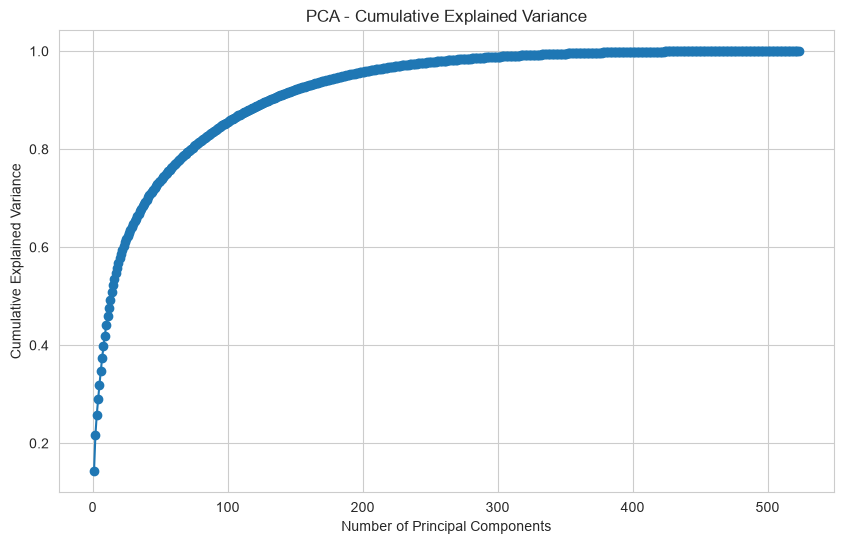

In [20]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), cumulative_var, marker="o", linestyle="-")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.grid(True)
plt.show()

### K-Means clustering and optimal number of clusters

In [21]:
silhouette_scores = []
rand_scores = []

In [22]:
for k in range(2, 7):    
    kmeans = KMeans(n_clusters=k, random_state=42)
    cluster_labels = kmeans.fit_predict(X_pca_50)    # PCA with 50 components is 

    # Silhouette 
    sil = silhouette_score(X_pca_50, cluster_labels, sample_size=min(5000, len(X_pca_50)), random_state=42)
    silhouette_scores.append(sil)

    # Adjusted Rand Index 
    ari = adjusted_rand_score(y, cluster_labels)
    rand_scores.append(ari)

    print(f"k={k}: Silhouette={sil:.4f}, Adjusted Rand Index={ari:.4f}")

k=2: Silhouette=0.1476, Adjusted Rand Index=0.3606
k=3: Silhouette=0.1284, Adjusted Rand Index=0.5175
k=4: Silhouette=0.1072, Adjusted Rand Index=0.4536
k=5: Silhouette=0.1040, Adjusted Rand Index=0.5087
k=6: Silhouette=0.1000, Adjusted Rand Index=0.4812


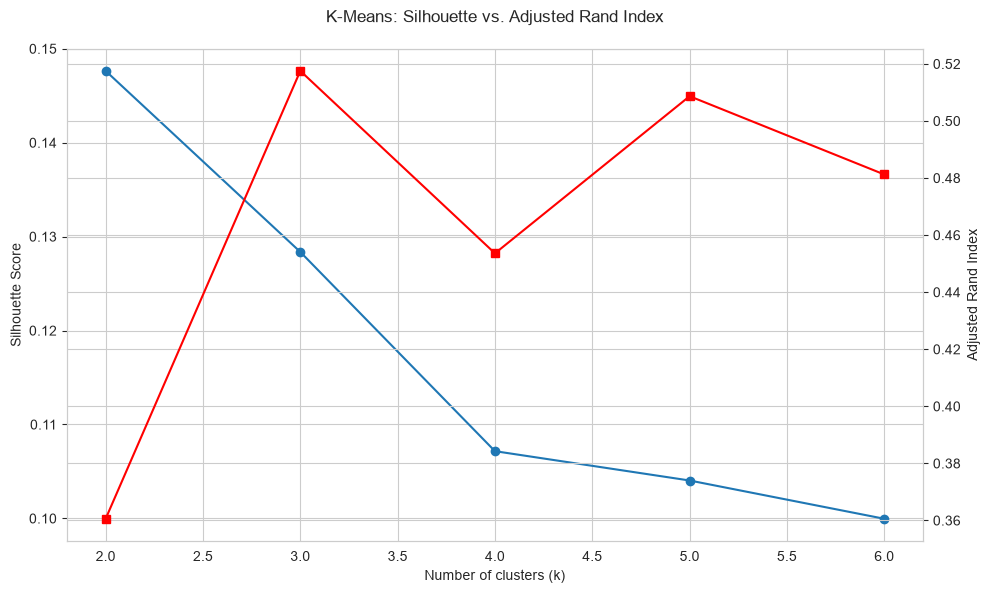

In [23]:
# Plot the metrics
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Silhouette Score")
ax1.plot([2, 3, 4, 5, 6], silhouette_scores, marker="o", label="Silhouette")

ax2 = ax1.twinx()
ax2.set_ylabel("Adjusted Rand Index")
ax2.plot([2, 3, 4, 5, 6], rand_scores, color='red', marker="s", label="Rand Index")

fig.suptitle("K-Means: Silhouette vs. Adjusted Rand Index")
fig.tight_layout()
plt.show()

In [24]:
best_k_sil = [2, 3, 4, 5, 6][np.argmax(silhouette_scores)]
best_k_ari = [2, 3, 4, 5, 6][np.argmax(rand_scores)]

In [25]:
print(f"Optimal k by Silhouette: {best_k_sil}")
print(f"Optimal k by Rand Index: {best_k_ari}")

Optimal k by Silhouette: 2
Optimal k by Rand Index: 3


### Whether visualization results from p.3 reflects the real distribution of the genres? Which algorithm performs better and why?

**t-SNE generally performs better for visual separation of genres**. t-SNE is a non-linear technique designed to preserve local neighbourhoods, so it tends to create well-separated clusters that often align with genre boundaries. PCA, being a linear method, preserves global variance but may not capture the nonlinear manifold structure of audio features, so genres may appear more overlapping.

However, **neither visualization is a faithful reflection of the “real” distribution**. t-SNE can create artificial clusters even in random data and can distort global distances. PCA is more faithful to global geometry but may fail to separate genres that differ only in nonlinear feature combinations. 

### What percentage of the explained variance was left after we have excluded all but 2 components in p.4?

In [26]:
# Percentage of variance left after keeping only 2 components
var_2_components = cumulative_var[1] * 100
print(f"Explained variance retained by first 2 PCs: {var_2_components:.2f}%")
print(f"Variance LOST (excluded) after keeping only 2 PCs: {100 - var_2_components:.2f}%")

Explained variance retained by first 2 PCs: 21.60%
Variance LOST (excluded) after keeping only 2 PCs: 78.40%


This means that a 2D PCA plot captures only about a quarter of the total information, which is one reason why genre separation in PCA space may be imperfect.

### Can Silhouette metric be chosen as optimal criteria for the number of clusters for that data? Is Rand index is more appropriate?

**Silhouette score is an unsupervised criterion** and can be used to choose `k` when no ground-truth labels are available. However, **it may not select the “true” number of genres**, because it measures geometric cohesion/separation. In music data, the most “compact” clustering may correspond to broad style groupings (e.g., “acoustic vs. electronic”) rather than the nuanced genre taxonomy.

**Adjusted Rand Index (ARI)** uses the known genre labels and therefore directly measures how well the clusters match the real genres. If the goal is to recover the genre structure, **ARI is more appropriate for evaluating clustering quality**. Nevertheless, ARI is not a criterion for choosing `k`, it is an evaluation metric. For model selection, one could choose the `k` that maximises ARI if genre labels are available, but this is technically supervised model selection.

### If you don’t know the genre but need to build a song recommendation system based on the similarity between the songs in this dataset - what would you do?

Without genre labels, I would build a content-based recommendation system using the audio features:

- **Preprocess** the features (impute missing values, standardize).
- **Reduce dimensionality** with PCA (e.g., keep enough components to explain 90–95 % of variance) to denoise and speed up similarity computation.
- **Define a similarity metric** – cosine similarity or Euclidean distance in the reduced feature space.
- **Recommend** the most similar songs to a given song.

Optionally, I could use **K-Means clustering** to group songs into `k` clusters and recommend songs from the same cluster. A hybrid approach (cluster + nearest neighbours within cluster) can also work. The recommendation is often driven by acoustic similarity, not by genre labels.

### How do you think, what is the most important feature (from the initial dataset) for the cluster division?

We can train a **Random Forest classifier** on the genre labels and inspect `feature_importances_`

In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer      # to impute missing values with median 

In [28]:
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

In [29]:
# Train a random forest classifier
rf = RandomForestClassifier(random_state=42)
rf.fit(X_imputed, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [30]:
# Get feature importances
importances = rf.feature_importances_
feature_names = X.columns  # original feature names

In [31]:
# Top 5 features
indices = np.argsort(importances)[::-1][:5]
top_features = [(feature_names[i], importances[i]) for i in indices]

In [32]:
print("Top 5 most important features for genre classification:")
for name, imp in top_features:
    print(f"{name}: {imp:.4f}")

Top 5 most important features for genre classification:
mfcc_max_04: 0.0335
mfcc_mean_04: 0.0299
mfcc_median_04: 0.0256
spectral_centroid_kurtosis_01: 0.0228
spectral_rolloff_skew_01: 0.0222
